# 04 · The Embedders I — Static Word Embeddings (GloVe)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Cecile1015/emotion-mirror-cbs4702/blob/main/notebooks/04_static_embeddings.ipynb)

Improvement 2 replaces the sparse word features of Steps 2–3 with **dense, pre-trained word embeddings** (Lecture 6). This notebook keeps the classifier fixed — multinomial logistic regression, as in every earlier model — and changes only the representation: each text becomes the **average of its GloVe word vectors**. The next notebook (`05_bilstm`) keeps the same GloVe vectors and adds **word order** with a bidirectional LSTM (Lecture 7).

| Model id | Representation (L6) | Classifier (L5) | Tuned on validation |
|---|---|---|---|
| `glove_twitter_lr` | mean of GloVe Twitter vectors (200-d) | softmax LR on standardised features | `C`, class weights |
| `glove_wiki_lr` | mean of GloVe Wikipedia + Gigaword vectors (300-d) | softmax LR on standardised features | `C`, class weights |
| `glove_lr` | role name: the variant selected on validation | | |

Questions answered here:

1. How much of the vocabulary of the dataset do the two pre-trained tables cover, in particular the words that never occur in the training set? (§3)
2. Which pre-training corpus gives the better averaged sentence vectors — informal tweets or edited Wikipedia/news text? (§4–5, controlled comparison)
3. Is the averaging step itself the bottleneck? (§5.2, pooling diagnostic on validation)
4. How does the dense representation compare with the best sparse model of Step 3 on the test set? (§7)

All selection decisions use the validation split; the test split is used once, in §6–7.

In [1]:
# Environment setup: runs locally (from the project root or notebooks/) and on Google Colab.
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/Cecile1015/emotion-mirror-cbs4702.git"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    # Colab already provides every package this notebook needs; only the repository is cloned.
    ROOT = Path("/content/emotion-mirror-cbs4702")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(ROOT)], check=True)
    os.chdir(ROOT / "notebooks")
else:
    ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()

sys.path.insert(0, str(ROOT))
print(f"Project root: {ROOT} | running on Colab: {IN_COLAB}")

Project root: /Users/yin/Desktop/6-polyu year3 semester1/CBS4702 Advanced Topics in Quantitative Language Studies/emotion-mirror-cbs4702 | running on Colab: False


In [2]:
import json
import re
import time
from collections import Counter

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, log_loss
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from src.config import EMOTION_COLORS, FIG_DIR, LABELS, METRICS_DIR, MODELS_DIR, PRED_DIR, SEED, ensure_dirs, set_seed
from src.data import load_splits, tokenize
from src.embeddings import GLOVE_VARIANTS, MeanEmbeddingVectorizer, coverage, load_glove
from src.evaluate import (
    evaluate,
    mcnemar_test,
    paired_bootstrap,
    plot_confusion_matrix,
    plot_per_class_f1,
    summary_table,
)
from src.slices import training_vocabulary, unseen_word_mask

set_seed(SEED)
ensure_dirs()
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.titleweight": "bold"})

# Every scikit-learn model of the project is saved in this folder.
CLASSICAL_DIR = MODELS_DIR / "classical"
CLASSICAL_DIR.mkdir(parents=True, exist_ok=True)
LABEL_IDS = list(range(len(LABELS)))
print(f"scikit-learn {sklearn.__version__}")


def savefig(fig, name):
    fig.savefig(FIG_DIR / name, bbox_inches="tight")


def macro_f1(y_true, y_pred):
    # Primary selection metric: unweighted mean of the six per-class F1 scores.
    return f1_score(y_true, y_pred, labels=LABEL_IDS, average="macro", zero_division=0)

scikit-learn 1.9.1


## 1. Data

The official splits are loaded from the local cache (train 16,000 / validation 2,000 / test 2,000). Texts are tokenised with the project tokenizer `src.data.tokenize` (lower-case word tokens; the dataset has no punctuation). The reference models of Steps 2–3 are loaded from their saved prediction files, so `02_baselines` and `03_improved_classical` must have been run first.

In [3]:
splits = load_splits()
train, val, test = splits["train"], splits["validation"], splits["test"]

X_train, y_train = train["text"].tolist(), train["label"].to_numpy()
X_val, y_val = val["text"].tolist(), val["label"].to_numpy()
X_test, y_test = test["text"].tolist(), test["label"].to_numpy()

tokens = {name: [tokenize(t) for t in X] for name, X in [("train", X_train), ("validation", X_val), ("test", X_test)]}
train_vocab = training_vocabulary(X_train)  # shared definition from src/slices.py (Step 3)

# Sparse reference models (Steps 2-3); their saved predictions are used for the paired tests.
REFERENCE = {"tfidf_lr": "TF-IDF + LR (Step 2)", "improved_lr": "Improved sparse LR (Step 3)"}
missing = [m for m in REFERENCE for s in ("validation", "test") if not (PRED_DIR / f"{m}__{s}.csv").exists()]
assert not missing, f"Run 02_baselines and 03_improved_classical first; missing predictions for {missing}"
reference_preds = {
    split: {m: pd.read_csv(PRED_DIR / f"{m}__{split}.csv")["pred"].to_numpy() for m in REFERENCE}
    for split in ("validation", "test")
}

for name, y in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    print(f"{name:<11} n = {len(y):>6,}")
print(f"training vocabulary: {len(train_vocab):,} word types")

train       n = 16,000
validation  n =  2,000
test        n =  2,000
training vocabulary: 15,212 word types


## 2. Pre-trained GloVe vectors

### 2.1 From sparse to dense word representations (Lecture 6)

In the bag-of-words and TF-IDF models every word type is its own dimension: *sad* and *unhappy* are as different as *sad* and *table*, and a word that never occurs in the training set has no weight at all. Distributional semantics replaces this one-hot view with the **distributional hypothesis** — words that occur in similar contexts have similar meanings — and represents each word by a short **dense vector** learned from co-occurrence statistics of a large unlabelled corpus.

**GloVe** (Global Vectors; Pennington et al., 2014) fits word vectors $\mathbf{w}_i$ and context vectors $\tilde{\mathbf{w}}_j$ so that their dot product approximates the logarithm of the co-occurrence count $X_{ij}$:

$$
J = \sum_{i,j} f(X_{ij})\,\bigl(\mathbf{w}_i^{\top}\tilde{\mathbf{w}}_j + b_i + \tilde{b}_j - \log X_{ij}\bigr)^2 ,
$$

where $f$ down-weights very rare and very frequent pairs. The result is a **static** embedding: one vector per word type, the same in every sentence (in contrast with the contextual BERT vectors of Step 5).

### 2.2 The two variants

The two tables differ in the pre-training corpus and in the dimension, which is the trade-off this notebook measures. The files are the official Stanford vectors as redistributed by the `gensim-data` project; `src/embeddings.py` downloads each file once (≈ 0.8 GB and 0.4 GB) into `data/embeddings/` (not committed to git) and caches the word types that the project tokenizer can produce (words of lower-case letters). Entries such as hashtags, numbers, emoticons or non-Latin words can never be looked up for this dataset, so dropping them changes no result.

In [4]:
VARIANTS = ["twitter200", "wiki300"]
VARIANT_NAMES = {"twitter200": "GloVe Twitter-200", "wiki300": "GloVe Wiki-Gigaword-300"}

glove = {}
rows = []
for name in VARIANTS:
    start = time.perf_counter()
    glove[name] = load_glove(name)  # downloads and builds the cache on the first run (a few minutes)
    meta = GLOVE_VARIANTS[name]
    rows.append({
        "variant": VARIANT_NAMES[name],
        "pre-training corpus": meta.corpus,
        "dimension": meta.dim,
        "original vocabulary": meta.vocab_size,
        "types kept (letter words)": len(glove[name]),
        "load seconds": round(time.perf_counter() - start, 1),
    })
display(pd.DataFrame(rows).set_index("variant"))

glove-twitter-200.gz:   0%|          | 0.00/795M [00:00<?, ?B/s]

glove-wiki-gigaword-300.gz:   0%|          | 0.00/394M [00:00<?, ?B/s]

,pre-training corpus,dimension,original vocabulary,types kept (letter words),load seconds
variant,,,,,
GloVe Twitter-200,"Twitter: 2B tweets, 27B tokens",200,1193514,555577,98.0
GloVe Wiki-Gigaword-300,Wikipedia 2014 + Gigaword 5: 6B tokens,300,400000,318650,49.2


### 2.3 What the vectors encode: nearest neighbours

Cosine similarity, $\cos(\mathbf{u}, \mathbf{v}) = \mathbf{u}^{\top}\mathbf{v} / (\lVert\mathbf{u}\rVert\,\lVert\mathbf{v}\rVert)$, measures how similar the contexts of two words are. The table lists the nearest neighbours of one cue word per emotion among the 50,000 most frequent words of each table.

In [5]:
CUE_WORDS = {"sadness": "sad", "joy": "happy", "love": "loving", "anger": "angry", "fear": "scared", "surprise": "surprised"}

neighbour_table = pd.DataFrame({
    VARIANT_NAMES[name]: {
        f"{emotion}: {cue}": ", ".join(w for w, _ in glove[name].most_similar(cue, k=7))
        for emotion, cue in CUE_WORDS.items()
    }
    for name in VARIANTS
})
with pd.option_context("display.max_colwidth", None):
    display(neighbour_table)

,GloVe Twitter-200,GloVe Wiki-Gigaword-300
sadness: sad,"depressing, really, depressed, sick, feel, cry, upset","sorry, tragic, happy, unfortunate, terribly, pathetic, awful"
joy: happy,"birthday, day, bday, wish, merry, love, year","glad, pleased, really, always, everyone, everybody, feel"
love: loving,"loved, love, lovin, seeing, giving, always, being","caring, love, loved, affectionate, passionate, affection, gentle"
anger: angry,"birds, mad, annoyed, upset, frustrated, pissed, confused","enraged, furious, irate, outraged, frustrated, angered, provoked"
fear: scared,"afraid, scary, terrified, worried, pissed, mad, scare","frightened, afraid, terrified, worried, fearful, tired, intimidated"
surprise: surprised,"shocked, disappointed, suprised, impressed, pissed, thought, upset","disappointed, pleased, shocked, stunned, impressed, amazed, thrilled"


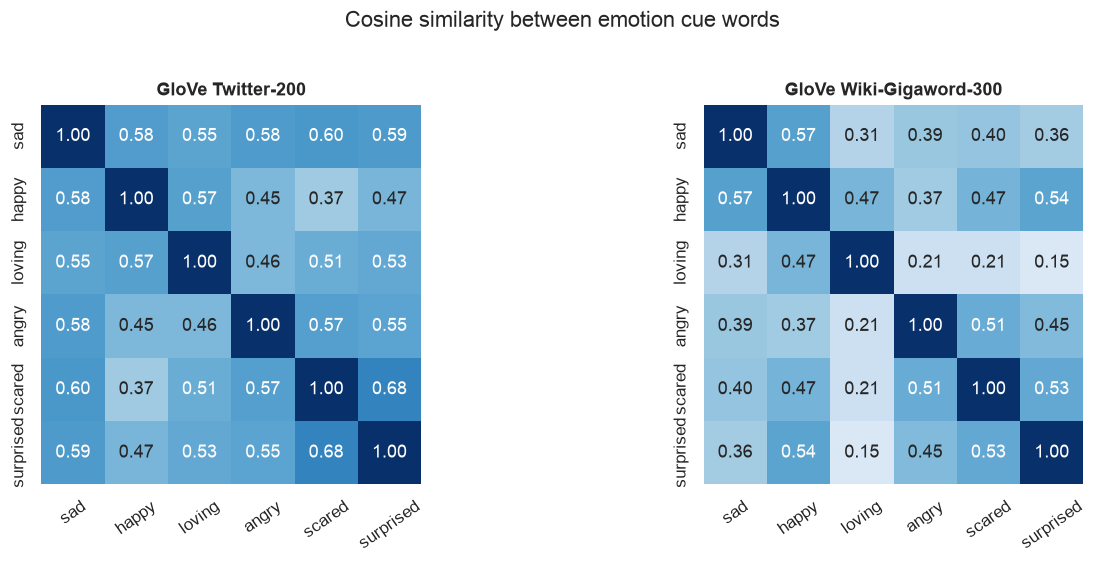

GloVe Twitter-200        cos(happy, sad) = 0.58 | mean similarity between different cue words = 0.54
GloVe Wiki-Gigaword-300  cos(happy, sad) = 0.57 | mean similarity between different cue words = 0.40


In [6]:
cues = list(CUE_WORDS.values())
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5))
similarity = {}
for ax, name in zip(axes, VARIANTS):
    sim = pd.DataFrame([[glove[name].similarity(a, b) for b in cues] for a in cues], index=cues, columns=cues)
    similarity[name] = sim
    sns.heatmap(sim, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, square=True, cbar=False, ax=ax)
    ax.tick_params(axis="x", rotation=35)
    ax.set_title(VARIANT_NAMES[name])
fig.suptitle("Cosine similarity between emotion cue words", y=1.02)
fig.tight_layout()
savefig(fig, "embeddings_cue_word_similarity.png")
plt.show()

off_diag = {name: similarity[name].where(~np.eye(len(cues), dtype=bool)).stack() for name in VARIANTS}
for name in VARIANTS:
    print(f"{VARIANT_NAMES[name]:<24} cos(happy, sad) = {glove[name].similarity('happy', 'sad'):.2f} | "
          f"mean similarity between different cue words = {off_diag[name].mean():.2f}")

The neighbour lists show what each corpus has learned. Emotion words share their contexts (*I feel ___*, *so ___*, *makes me ___*), so their vectors lie close together even when their meanings are opposite: the distributional hypothesis captures **relatedness**, not **polarity**. This is a known limitation of count-based and predictive embeddings and is the first reason to expect that a plain average of GloVe vectors will separate the six emotions less sharply than the word identities used by the sparse models.

## 3. Vocabulary coverage

A word can only contribute to a sentence vector if it has a pre-trained vector. Coverage is measured in two ways:

* **type coverage** — the share of distinct word types with a vector;
* **token coverage** — the share of running words with a vector (frequent words count more).

The most important number for generalisation is the coverage of words that **do not occur in the training set**. A sparse model has no feature for such a word, whereas an embedding model can still place it near known words. `01_eda` found that 31.5% of the test texts contain at least one such word.

In [7]:
coverage_rows, missing_words = [], {}
for name in VARIANTS:
    for split in ("train", "validation", "test"):
        cov = coverage(tokens[split], glove[name])
        row = {
            "variant": VARIANT_NAMES[name],
            "split": split,
            "types": cov["types"],
            "type coverage": cov["type_coverage"],
            "token coverage": cov["token_coverage"],
        }
        if split == "train":
            missing_words[name] = Counter(cov["missing"])
        else:
            unseen = {w for toks in tokens[split] for w in toks if w not in train_vocab}
            has_unseen = unseen_word_mask(X_val if split == "validation" else X_test, train_vocab)
            all_unseen_covered = np.array([
                all(w in glove[name] for w in toks if w not in train_vocab) for toks in tokens[split]
            ])
            row.update({
                "unseen-in-train types": len(unseen),
                "unseen types with a vector": np.mean([w in glove[name] for w in unseen]),
                "texts with an unseen word": has_unseen.mean(),
                "...of which every unseen word has a vector": all_unseen_covered[has_unseen].mean(),
            })
        coverage_rows.append(row)

coverage_table = pd.DataFrame(coverage_rows).set_index(["variant", "split"])
coverage_table.to_csv(METRICS_DIR / "coverage_static_embeddings.csv")
display(coverage_table.style.format({c: "{:.1%}" for c in coverage_table.columns if c not in ("types", "unseen-in-train types")}
                                    | {"types": "{:,.0f}", "unseen-in-train types": "{:,.0f}"}, na_rep="—"))

In [8]:
missing_table = pd.DataFrame({
    VARIANT_NAMES[name]: [f"{w} ({c})" for w, c in missing_words[name].most_common(15)] for name in VARIANTS
})
missing_table.index = range(1, 16)
print("Most frequent training-set words without a GloVe vector (count in train)")
display(missing_table)

for name in VARIANTS:
    share = MeanEmbeddingVectorizer(name).fit(X_train).known_token_share(X_test)
    print(f"{VARIANT_NAMES[name]:<24} test texts without any known token: {np.sum(share == 0)} | "
          f"median share of known tokens per text: {np.median(share):.1%}")

Most frequent training-set words without a GloVe vector (count in train)


,GloVe Twitter-200,GloVe Wiki-Gigaword-300
1,pagetitle (7),href (160)
2,twinges (3),shouldnt (27)
3,siwons (2),hadnt (16)
4,percieve (2),youve (11)
5,vbac (2),hadn (9)
6,undesired (2),nofollow (8)
7,amvassago (2),theyd (7)
8,adomen (2),pagetitle (7)
9,unza (2),werent (7)
10,complainy (2),everyones (5)


GloVe Twitter-200        test texts without any known token: 0 | median share of known tokens per text: 100.0%
GloVe Wiki-Gigaword-300  test texts without any known token: 0 | median share of known tokens per text: 100.0%


Both tables cover more than 99.5% of the running words, and they recover most of the words that are absent from the training set — the advantage of pre-training on billions of tokens. The words they miss are informative about the corpora: the Wikipedia/news table has no vectors for apostrophe-less contractions (*shouldnt*, *hadnt*, *youve*), which are written with an apostrophe in edited text, nor for HTML residue (*href*); the Twitter table knows these informal spellings, and its gaps are mostly misspellings and rare names.

## 4. Averaged sentence vectors + logistic regression

### 4.1 Representation and classifier

A text $d$ with tokens $t_1, \dots, t_n$ is represented by the mean of the vectors of the tokens that have one,

$$
\mathbf{x}_d = \frac{1}{|K_d|} \sum_{t \in K_d} \mathbf{v}_t, \qquad K_d = \{\, t_i : t_i \text{ has a GloVe vector} \,\},
$$

and $\mathbf{x}_d = \mathbf{0}$ if no token is known. This is a **bag of embeddings**: like bag-of-words it ignores word order, but each word now contributes a 200- or 300-dimensional dense vector instead of a single sparse feature. The classifier is the same softmax logistic regression as before (L5), $P(y = c \mid \mathbf{x}) = \operatorname{softmax}(W\mathbf{x} + \mathbf{b})_c$.

Unlike TF-IDF features, the averaged dimensions have different scales, so the features are **standardised** (zero mean, unit variance on the training split) before the L2-regularised LR; otherwise the penalty would act unevenly across dimensions. The pipeline `MeanEmbeddingVectorizer → StandardScaler → LogisticRegression` accepts raw strings, exactly like the sparse pipelines.

### 4.2 Hyper-parameter selection on the validation set

`C` (inverse regularisation strength) is searched on a log grid, with and without balanced class weights (which helped the sparse model in Step 3). The selection rule is unchanged: highest validation macro-F1; ties go to the smaller `C`. As in Steps 2–3, `LogisticRegression(tol=1e-6, max_iter=5000)` makes the solution independent of the scikit-learn version. The sentence vectors are computed once per split, which is equivalent to refitting the full pipeline for every grid point because the vectoriser has no trainable parameters.

In [9]:
vectorisers = {name: MeanEmbeddingVectorizer(name).fit(X_train) for name in VARIANTS}
features = {
    name: {"train": vec.transform(X_train), "validation": vec.transform(X_val), "test": vec.transform(X_test)}
    for name, vec in vectorisers.items()
}

C_GRID = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0, 100.0]
CLASS_WEIGHTS = [None, "balanced"]


def tune_dense(name, feats, c_grid=C_GRID, class_weights=CLASS_WEIGHTS, label=None):
    # Fit StandardScaler + LR on train for every (C, class_weight) and score on validation.
    scaler = StandardScaler().fit(feats["train"])
    Xtr, Xva = scaler.transform(feats["train"]), scaler.transform(feats["validation"])
    rows = []
    for cw in class_weights:
        for c in c_grid:
            clf = LogisticRegression(C=c, class_weight=cw, tol=1e-6, max_iter=5000, random_state=SEED)
            start = time.perf_counter()
            clf.fit(Xtr, y_train)
            val_pred = clf.predict(Xva)
            rows.append({
                "variant": label or name,
                "C": c,
                "class_weight": cw or "none",
                "train_macro_f1": macro_f1(y_train, clf.predict(Xtr)),
                "val_accuracy": float(np.mean(val_pred == y_val)),
                "val_macro_f1": macro_f1(y_val, val_pred),
                "fit_seconds": time.perf_counter() - start,
            })
    return pd.DataFrame(rows)


def select_best(log):
    # Highest validation macro-F1 (rounded to 4 decimals); ties go to the smaller C.
    ordered = log.assign(score=log["val_macro_f1"].round(4)).sort_values(["score", "C"], ascending=[False, True])
    return ordered.iloc[0]


tuning_log = pd.concat([tune_dense(name, features[name]) for name in VARIANTS], ignore_index=True)
tuning_log.to_csv(METRICS_DIR / "tuning_static_embeddings_validation.csv", index=False)

best = {name: select_best(tuning_log[tuning_log["variant"] == name]) for name in VARIANTS}
selection = pd.DataFrame({
    VARIANT_NAMES[name]: {
        "C": b["C"],
        "class weights": b["class_weight"],
        "val macro-F1": b["val_macro_f1"],
        "val accuracy": b["val_accuracy"],
        "train macro-F1": b["train_macro_f1"],
        "train − val gap": b["train_macro_f1"] - b["val_macro_f1"],
    }
    for name, b in best.items()
}).T
display(selection.style.format({"C": "{:g}", "val macro-F1": "{:.4f}", "val accuracy": "{:.4f}",
                                "train macro-F1": "{:.4f}", "train − val gap": "{:+.4f}"}))

,C,class weights,val macro-F1,val accuracy,train macro-F1,train − val gap
GloVe Twitter-200,0.1,none,0.5840,0.6710,0.6045,+0.0206
GloVe Wiki-Gigaword-300,3,none,0.6432,0.6975,0.6636,+0.0204


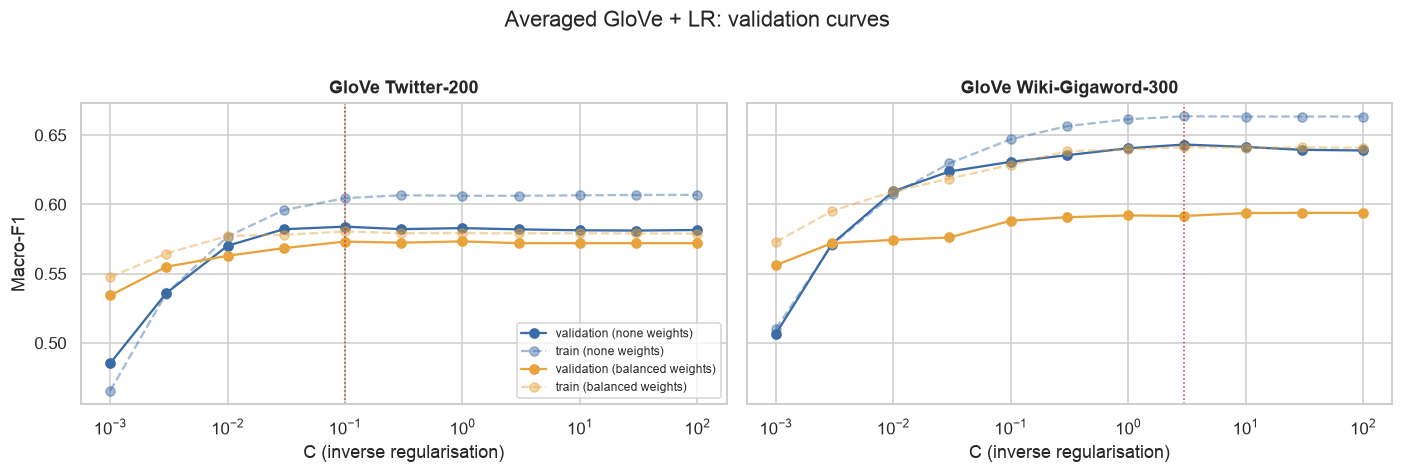

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, name in zip(axes, VARIANTS):
    log = tuning_log[tuning_log["variant"] == name]
    for cw, color in [("none", "#3B6BA5"), ("balanced", "#E8A33D")]:
        part = log[log["class_weight"] == cw]
        ax.plot(part["C"], part["val_macro_f1"], "o-", color=color, label=f"validation ({cw} weights)")
        ax.plot(part["C"], part["train_macro_f1"], "o--", color=color, alpha=0.45, label=f"train ({cw} weights)")
    ax.axvline(best[name]["C"], color="#C0392B", lw=1, ls=":")
    ax.set_xscale("log")
    ax.set_xlabel("C (inverse regularisation)")
    ax.set_title(VARIANT_NAMES[name])
axes[0].set_ylabel("Macro-F1")
axes[0].legend(fontsize=8, loc="lower right")
fig.suptitle("Averaged GloVe + LR: validation curves", y=1.02)
fig.tight_layout()
savefig(fig, "embeddings_validation_curves.png")
plt.show()

The curves are almost flat beyond a small `C` and the training and validation scores stay close together. This is the signature of **high bias**: even an almost unregularised linear model cannot fit the training texts well from averaged vectors (the sparse LR of Step 2 reached a training macro-F1 above 0.99). The limitation lies in the representation, not in the amount of regularisation.

## 5. Controlled comparison and pooling diagnostic (validation)

### 5.1 Twitter-200 vs Wiki-Gigaword-300

The two variants share the tokenizer, the averaging, the scaler, the classifier and the tuning grid, so the difference in the table above is attributable to the pre-trained table alone. Two factors change together — corpus and dimension — and they cannot be separated with these two files; §8 discusses which one is the more plausible cause.

### 5.2 Is the average the bottleneck?

The mean gives every token the same weight, so the template words *i*, *feel*, *that* and *the* dominate most sentence vectors. Two common alternatives are scored on validation with the selected class-weight setting and a re-tuned `C`:

* **idf-weighted mean** — each vector is weighted by its training-set idf (the same formula as `TfidfVectorizer`), which down-weights *feel* and function words;
* **mean ⊕ max pooling** — the mean is concatenated with the element-wise maximum over tokens, which can preserve a strong signal from a single word.

These variants are a diagnostic only; the reported model keeps the plain mean.

In [11]:
n_docs = len(tokens["train"])
doc_freq = Counter(w for toks in tokens["train"] for w in set(toks))


def idf(word):
    # Smoothed idf of scikit-learn's TfidfVectorizer; unseen words get the maximum value.
    return np.log((1 + n_docs) / (1 + doc_freq.get(word, 0))) + 1


def pooled_features(table, token_lists, mode):
    # Sentence vectors with "idf" weighting or "meanmax" pooling.
    dim = table.dim * (2 if mode == "meanmax" else 1)
    out = np.zeros((len(token_lists), dim), dtype=np.float32)
    for i, toks in enumerate(token_lists):
        known = [t for t in toks if t in table.index]
        if not known:
            continue
        vectors = table.vectors[[table.index[t] for t in known]]
        if mode == "idf":
            weights = np.array([idf(t) for t in known])
            out[i] = weights @ vectors / weights.sum()
        else:
            out[i] = np.concatenate([vectors.mean(axis=0), vectors.max(axis=0)])
    return out


pooling_rows = []
for name in VARIANTS:
    cw = None if best[name]["class_weight"] == "none" else best[name]["class_weight"]
    pooling_rows.append({"variant": VARIANT_NAMES[name], "pooling": "mean (selected)",
                         "C": best[name]["C"], "val_macro_f1": best[name]["val_macro_f1"]})
    for mode, label in [("idf", "idf-weighted mean"), ("meanmax", "mean ⊕ max")]:
        feats = {s: pooled_features(glove[name], tokens[s], mode) for s in ("train", "validation")}
        b = select_best(tune_dense(name, feats, class_weights=[cw]))
        pooling_rows.append({"variant": VARIANT_NAMES[name], "pooling": label, "C": b["C"], "val_macro_f1": b["val_macro_f1"]})

pooling = pd.DataFrame(pooling_rows)
pooling.to_csv(METRICS_DIR / "pooling_static_embeddings_validation.csv", index=False)
display(pooling.pivot(index="pooling", columns="variant", values="val_macro_f1").round(4))

variant,GloVe Twitter-200,GloVe Wiki-Gigaword-300
pooling,,
idf-weighted mean,0.5683,0.6301
mean (selected),0.5840,0.6432
mean ⊕ max,0.6443,0.6693


## 6. Final training and test evaluation

Each variant is refitted on the training split with its selected hyper-parameters and scored through `src/evaluate.py` on validation and test. The fitted pipelines are saved to `models/classical/<model>.joblib`. The GloVe table itself is **not** stored in the file (it would add 0.4 GB); `MeanEmbeddingVectorizer` re-attaches it from `data/embeddings/` when the pipeline is loaded, and downloads it if the cache is missing.

The variant with the higher validation macro-F1 is also saved under the role name `glove_lr`, which the comparisons below and the web application use. The selection is written to `results/metrics/selection_static_embeddings.json`, so that `05_bilstm` initialises its embedding layer with the same table.

In [12]:
MODEL_IDS = {"twitter200": "glove_twitter_lr", "wiki300": "glove_wiki_lr"}
DISPLAY_NAMES = {**REFERENCE, "glove_twitter_lr": "GloVe-Twitter-200 + LR", "glove_wiki_lr": "GloVe-Wiki-300 + LR"}


def make_pipeline(name, c, class_weight):
    cw = None if class_weight == "none" else class_weight
    return Pipeline([
        ("vec", MeanEmbeddingVectorizer(name)),
        ("scale", StandardScaler()),
        ("clf", LogisticRegression(C=c, class_weight=cw, tol=1e-6, max_iter=5000, random_state=SEED)),
    ])


final_models, preds, probas = {}, {"validation": {}, "test": {}}, {"validation": {}, "test": {}}
for name, model_id in MODEL_IDS.items():
    b = best[name]
    model = make_pipeline(name, b["C"], b["class_weight"]).fit(X_train, y_train)
    final_models[model_id] = model
    notes = (f"mean of {VARIANT_NAMES[name]} vectors (project tokenizer, unknown words skipped) + StandardScaler "
             f"+ LogisticRegression(C={b['C']:g}, class_weight={b['class_weight']}); selected by validation macro-F1")
    for split, X, y in [("validation", X_val, y_val), ("test", X_test, y_test)]:
        proba = model.predict_proba(X)
        pred = proba.argmax(axis=1)
        evaluate(model_id, y, pred, split=split, y_proba=proba, texts=X, notes=notes)
        preds[split][model_id], probas[split][model_id] = pred, proba
    joblib.dump(model, CLASSICAL_DIR / f"{model_id}.joblib")

# Role name for the selected variant (same model, saved a second time for the web app and later notebooks).
selected_variant = max(VARIANTS, key=lambda n: (round(best[n]["val_macro_f1"], 4), -VARIANTS.index(n)))
selected_id = MODEL_IDS[selected_variant]
DISPLAY_NAMES["glove_lr"] = f"GloVe + LR ({VARIANT_NAMES[selected_variant].replace('GloVe ', '')})"
for split, X, y in [("validation", X_val, y_val), ("test", X_test, y_test)]:
    evaluate("glove_lr", y, preds[split][selected_id], split=split, y_proba=probas[split][selected_id], texts=X,
             notes=f"role name: {selected_id} (selected by validation macro-F1)", verbose=False)
    preds[split]["glove_lr"], probas[split]["glove_lr"] = preds[split][selected_id], probas[split][selected_id]
joblib.dump(final_models[selected_id], CLASSICAL_DIR / "glove_lr.joblib")

selection_record = {
    "selected_variant": selected_variant,
    "model_id": selected_id,
    "C": float(best[selected_variant]["C"]),
    "class_weight": best[selected_variant]["class_weight"],
    "val_macro_f1": {MODEL_IDS[n]: float(best[n]["val_macro_f1"]) for n in VARIANTS},
}
(METRICS_DIR / "selection_static_embeddings.json").write_text(json.dumps(selection_record, indent=2))
print(f"\nSelected on validation: {selected_id} -> saved as glove_lr")
for model_id in [*MODEL_IDS.values(), "glove_lr"]:
    print(f"models/classical/{model_id}.joblib  {(CLASSICAL_DIR / f'{model_id}.joblib').stat().st_size / 1024:.0f} KB")

glove_twitter_lr [validation]  accuracy=0.6715  macro-F1=0.5845  weighted-F1=0.6616
glove_twitter_lr [test]  accuracy=0.6550  macro-F1=0.5674  weighted-F1=0.6462
glove_wiki_lr [validation]  accuracy=0.6970  macro-F1=0.6424  weighted-F1=0.6937
glove_wiki_lr [test]  accuracy=0.6745  macro-F1=0.6015  weighted-F1=0.6710

Selected on validation: glove_wiki_lr -> saved as glove_lr
models/classical/glove_twitter_lr.joblib  11 KB
models/classical/glove_wiki_lr.joblib  16 KB
models/classical/glove_lr.joblib  16 KB


In [13]:
# Sanity check: a reloaded pipeline accepts raw strings and reproduces the saved predictions.
reloaded = joblib.load(CLASSICAL_DIR / "glove_lr.joblib")
assert np.array_equal(reloaded.predict(X_test), preds["test"]["glove_lr"])

# The emotion words in these sentences never occur in the training set: the sparse model has no
# feature for them, whereas the GloVe model places them near known emotion words.
sparse_model = joblib.load(CLASSICAL_DIR / "improved_lr.joblib")
demo = ["i feel euphoric", "i feel forlorn", "i am livid", "i was flabbergasted", "i feel overjoyed and gleeful"]
demo_table = pd.DataFrame({
    "words unseen in training": [", ".join(w for w in tokenize(t) if w not in train_vocab) for t in demo],
    "improved_lr (sparse)": [LABELS[i] for i in sparse_model.predict(demo)],
    "glove_lr": [LABELS[i] for i in reloaded.predict(demo)],
    "glove_lr confidence": reloaded.predict_proba(demo).max(axis=1).round(3),
}, index=demo)
demo_table

,words unseen in training,improved_lr (sparse),glove_lr,glove_lr confidence
i feel euphoric,euphoric,joy,joy,0.996
i feel forlorn,forlorn,joy,sadness,1.000
i am livid,livid,sadness,anger,0.815
i was flabbergasted,flabbergasted,sadness,surprise,0.872
i feel overjoyed and gleeful,"overjoyed, gleeful",joy,joy,0.931


## 7. Results

### 7.1 Summary tables

The validation table repeats the trivial floor from `01_eda` and the sparse models of Steps 2–3. The test table adds a 95% bootstrap confidence interval for macro-F1 (1,000 resamples of the 2,000 test texts).

In [14]:
ALL_IDS = ["tfidf_lr", "improved_lr", "glove_twitter_lr", "glove_wiki_lr"]

print("Validation split (used for model selection)")
display(summary_table(["dummy_most_frequent", "dummy_stratified"] + ALL_IDS, split="validation").round(3))

test_preds = {**reference_preds["test"], **preds["test"]}


def bootstrap_ci(y_true, y_pred, n_boot=1000, seed=SEED):
    # Percentile 95% confidence interval of macro-F1 over resampled test sets.
    rng = np.random.default_rng(seed)
    n = len(y_true)
    scores = [macro_f1(y_true[idx], y_pred[idx]) for idx in (rng.integers(0, n, n) for _ in range(n_boot))]
    return np.percentile(scores, [2.5, 97.5])


test_table = summary_table(ALL_IDS, split="test")
ci = {name: bootstrap_ci(y_test, test_preds[name]) for name in ALL_IDS}
test_table.insert(2, "macro_f1_ci95", [f"[{ci[n][0]:.3f}, {ci[n][1]:.3f}]" for n in ALL_IDS])
print("Test split (final evaluation)")
display(test_table.round(3))

Validation split (used for model selection)


,accuracy,macro_f1,weighted_f1,f1_sadness,f1_joy,f1_love,f1_anger,f1_fear,f1_surprise
model,,,,,,,,,
dummy_most_frequent,0.352,0.087,0.183,0.000,0.521,0.000,0.000,0.000,0.000
dummy_stratified,0.244,0.171,0.244,0.297,0.349,0.092,0.144,0.094,0.052
tfidf_lr,0.894,0.865,0.894,0.912,0.924,0.826,0.897,0.834,0.797
improved_lr,0.899,0.878,0.900,0.924,0.918,0.850,0.905,0.846,0.825
glove_twitter_lr,0.672,0.585,0.662,0.686,0.774,0.507,0.597,0.538,0.406
glove_wiki_lr,0.697,0.642,0.694,0.713,0.767,0.599,0.646,0.605,0.524


Test split (final evaluation)


,accuracy,macro_f1,macro_f1_ci95,weighted_f1,f1_sadness,f1_joy,f1_love,f1_anger,f1_fear,f1_surprise
model,,,,,,,,,,
tfidf_lr,0.882,0.832,"[0.808, 0.853]",0.880,0.919,0.910,0.761,0.876,0.833,0.694
improved_lr,0.885,0.843,"[0.820, 0.862]",0.888,0.925,0.910,0.774,0.886,0.860,0.701
glove_twitter_lr,0.655,0.567,"[0.539, 0.595]",0.646,0.684,0.751,0.456,0.549,0.543,0.421
glove_wiki_lr,0.674,0.601,"[0.573, 0.629]",0.671,0.709,0.741,0.503,0.620,0.606,0.429


### 7.2 Per-class F1 and confusion matrices

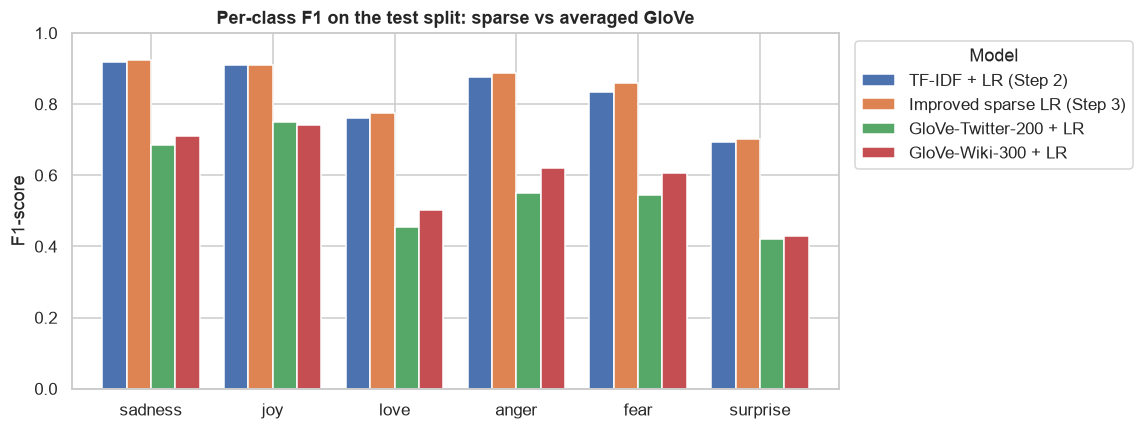

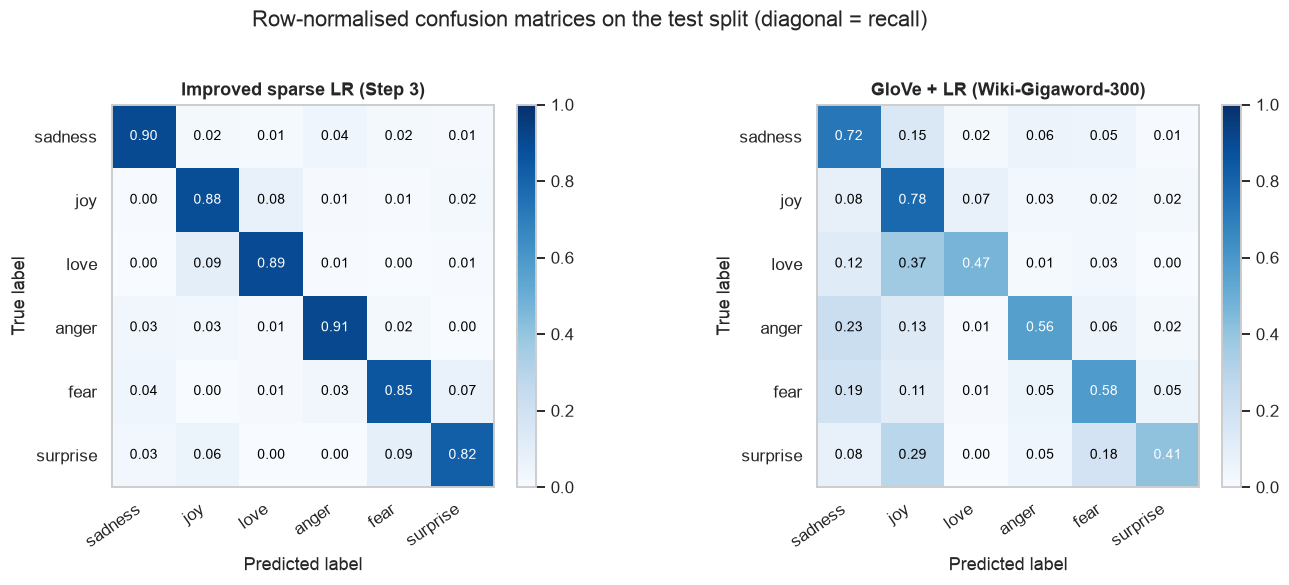

In [15]:
ax = plot_per_class_f1(
    test_table.drop(columns="macro_f1_ci95").rename(index=DISPLAY_NAMES),
    title="Per-class F1 on the test split: sparse vs averaged GloVe",
    save_as="embeddings_per_class_f1.png",
)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, name in zip(axes, ["improved_lr", "glove_lr"]):
    plot_confusion_matrix(y_test, test_preds[name], title=DISPLAY_NAMES[name], ax=ax)
fig.suptitle("Row-normalised confusion matrices on the test split (diagonal = recall)", y=1.02)
fig.tight_layout()
savefig(fig, "embeddings_confusion_matrices.png")
plt.show()

### 7.3 Significance of the controlled comparisons

Paired tests on the same 2,000 test texts, as in Steps 2–3: McNemar's test on the texts that exactly one model classifies correctly, and a paired bootstrap (2,000 resamples) of the macro-F1 difference $\Delta = \text{F1}_B - \text{F1}_A$. Because three comparisons are made, the McNemar p-values are also reported after the **Holm** correction for multiple testing.

In [16]:
def holm(p_values):
    # Holm step-down adjustment of a list of p-values (controls the family-wise error rate).
    p = np.asarray(p_values, dtype=float)
    order = np.argsort(p)
    adjusted = np.empty_like(p)
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (len(p) - rank) * p[i])
        adjusted[i] = min(1.0, running)
    return adjusted


COMPARISONS = [
    ("glove_twitter_lr", "glove_wiki_lr", "pre-training corpus: Twitter-200 → Wiki-300 (same averaging + LR)"),
    ("tfidf_lr", "glove_lr", "sparse TF-IDF (Step 2) → dense averaged GloVe (same LR)"),
    ("improved_lr", "glove_lr", "best sparse model (Step 3) → dense averaged GloVe"),
]

rows = []
for a, b, question in COMPARISONS:
    mc = mcnemar_test(y_test, test_preds[a], test_preds[b])
    bs = paired_bootstrap(y_test, test_preds[a], test_preds[b], n_boot=2000, seed=SEED)
    rows.append({
        "comparison (A → B)": f"{DISPLAY_NAMES[a]} → {DISPLAY_NAMES[b]}",
        "question": question,
        "b (only A correct)": mc["b"],
        "c (only B correct)": mc["c"],
        "McNemar p": mc["p_value"],
        "Δ macro-F1": bs["delta"],
        "95% CI of Δ": f"[{bs['ci_low']:+.3f}, {bs['ci_high']:+.3f}]",
    })
significance = pd.DataFrame(rows).set_index("comparison (A → B)")
significance.insert(5, "Holm p", holm(significance["McNemar p"]))
significance.to_csv(METRICS_DIR / "significance_static_embeddings_test.csv")
display(significance.style.format({"McNemar p": "{:.2g}", "Holm p": "{:.2g}", "Δ macro-F1": "{:+.3f}"}))

,question,b (only A correct),c (only B correct),McNemar p,Δ macro-F1,Holm p,95% CI of Δ
comparison (A → B),,,,,,,
GloVe-Twitter-200 + LR → GloVe-Wiki-300 + LR,pre-training corpus: Twitter-200 → Wiki-300 (same averaging + LR),237,276,0.093,+0.034,0.093,"[+0.004, +0.066]"
TF-IDF + LR (Step 2) → GloVe + LR (Wiki-Gigaword-300),sparse TF-IDF (Step 2) → dense averaged GloVe (same LR),474,60,1.9e-71,-0.231,5.8e-71,"[-0.259, -0.199]"
Improved sparse LR (Step 3) → GloVe + LR (Wiki-Gigaword-300),best sparse model (Step 3) → dense averaged GloVe,497,76,6.4e-69,-0.241,1.3e-68,"[-0.270, -0.211]"


### 7.4 Unseen words and text length

The one place where averaged GloVe should have a structural advantage is a text that contains a word never seen in training: the sparse model ignores the word, the embedding model does not. The test set is split into texts with and without such a word (31.5% / 68.5%, `01_eda`), and the macro-F1 difference between the two models is bootstrapped within each slice.

The two slices also differ in length (a longer text is more likely to contain a rare word), and an average is expected to blur more as more words enter it. The second table therefore scores both models by text-length quartile.

,n,median length,improved_lr macro-F1,glove_lr macro-F1,Δ (B − A),95% CI of Δ
test slice,,,,,,
contains an unseen word,630,23.0,0.835,0.508,-0.327,"[-0.382, -0.273]"
all words seen in training,1370,14.0,0.845,0.642,-0.203,"[-0.242, -0.169]"


,n,median length,improved_lr macro-F1,glove_lr macro-F1,Δ (B − A),95% CI of Δ
test slice,,,,,,
length 3–10,501,7.0,0.892,0.727,-0.165,"[-0.219, -0.119]"
length 11–17,531,14.0,0.877,0.606,-0.271,"[-0.335, -0.211]"
length 18–26,507,22.0,0.838,0.561,-0.277,"[-0.339, -0.218]"
length 27–61,461,33.0,0.758,0.492,-0.266,"[-0.335, -0.206]"


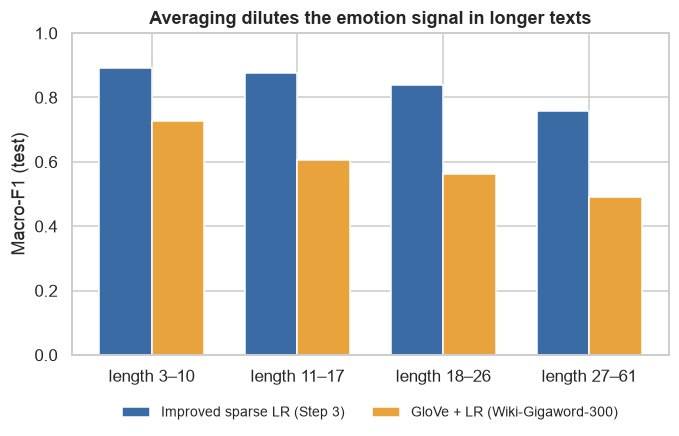

In [17]:
test_lengths = np.array([len(toks) for toks in tokens["test"]])
has_unseen = unseen_word_mask(X_test, train_vocab)


def slice_comparison(masks, a="improved_lr", b="glove_lr"):
    # Macro-F1 of two models and the bootstrapped difference within each test slice.
    rows = []
    for slice_name, mask in masks:
        yt, pa, pb = y_test[mask], test_preds[a][mask], test_preds[b][mask]
        bs = paired_bootstrap(yt, pa, pb, n_boot=2000, seed=SEED)
        rows.append({
            "test slice": slice_name,
            "n": int(mask.sum()),
            "median length": float(np.median(test_lengths[mask])),
            f"{a} macro-F1": macro_f1(yt, pa),
            f"{b} macro-F1": macro_f1(yt, pb),
            "Δ (B − A)": bs["delta"],
            "95% CI of Δ": f"[{bs['ci_low']:+.3f}, {bs['ci_high']:+.3f}]",
        })
    return pd.DataFrame(rows).set_index("test slice")


unseen_table = slice_comparison([("contains an unseen word", has_unseen), ("all words seen in training", ~has_unseen)])
length_bins = pd.qcut(test_lengths, 4)
length_masks = [(f"length {int(np.floor(iv.left)) + 1}–{iv.right:.0f}", length_bins == iv) for iv in length_bins.categories]
length_table = slice_comparison(length_masks)
pd.concat({"unseen words": unseen_table, "length quartiles": length_table}).to_csv(
    METRICS_DIR / "slices_static_embeddings_test.csv")
display(unseen_table.round(3))
display(length_table.round(3))

fig, ax = plt.subplots(figsize=(7, 3.8))
x = np.arange(len(length_table))
for model, color, offset in [("improved_lr", "#3B6BA5", -0.18), ("glove_lr", "#E8A33D", 0.18)]:
    ax.bar(x + offset, length_table[f"{model} macro-F1"], width=0.36, color=color, label=DISPLAY_NAMES[model])
ax.set_xticks(x, length_table.index)
ax.set_ylabel("Macro-F1 (test)")
ax.set_ylim(0, 1)
ax.set_title("Averaging dilutes the emotion signal in longer texts")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=9, frameon=False)
savefig(fig, "embeddings_length_dilution.png")
plt.show()

### 7.5 Probability quality and typical failures

In [18]:
reference_proba = {m: pd.read_csv(PRED_DIR / f"{m}__test.csv")[[f"p_{c}" for c in LABELS]].to_numpy() for m in REFERENCE}
calibration_rows = []
for name in ["tfidf_lr", "improved_lr", "glove_twitter_lr", "glove_wiki_lr"]:
    proba = reference_proba[name] if name in REFERENCE else probas["test"][name]
    confidence = proba.max(axis=1)
    correct = proba.argmax(axis=1) == y_test
    calibration_rows.append({
        "model": DISPLAY_NAMES[name],
        "test log-loss": log_loss(y_test, proba, labels=LABEL_IDS),
        "accuracy": correct.mean(),
        "mean confidence": confidence.mean(),
        "mean confidence (wrong)": confidence[~correct].mean(),
    })
display(pd.DataFrame(calibration_rows).set_index("model").round(3))

,test log-loss,accuracy,mean confidence,mean confidence (wrong)
model,,,,
TF-IDF + LR (Step 2),0.329,0.882,0.869,0.666
Improved sparse LR (Step 3),0.474,0.885,0.722,0.559
GloVe-Twitter-200 + LR,0.899,0.655,0.660,0.544
GloVe-Wiki-300 + LR,0.885,0.674,0.709,0.594


In [19]:
# Texts that the sparse model gets right and averaged GloVe gets wrong, most confident GloVe errors first.
glove_proba = probas["test"]["glove_lr"]
mask = (test_preds["improved_lr"] == y_test) & (preds["test"]["glove_lr"] != y_test)
examples = pd.DataFrame({
    "text": np.asarray(X_test)[mask],
    "gold": [LABELS[i] for i in y_test[mask]],
    "glove_lr": [LABELS[i] for i in preds["test"]["glove_lr"][mask]],
    "glove confidence": glove_proba[mask].max(axis=1),
}).sort_values("glove confidence", ascending=False)
print(f"sparse right, GloVe wrong: {mask.sum()} texts | GloVe right, sparse wrong: "
      f"{((test_preds['improved_lr'] != y_test) & (preds['test']['glove_lr'] == y_test)).sum()} texts")
with pd.option_context("display.max_colwidth", 110):
    display(examples.head(10).round(3))

sparse right, GloVe wrong: 497 texts | GloVe right, sparse wrong: 76 texts


,text,gold,glove_lr,glove confidence
259,i feel completely distracted and emotionally drained,anger,sadness,1.000
215,i feel defeated but its okay hahaha my mid term holiday was good,sadness,joy,0.996
242,i feel so special and when i want mashed potatoes pronto i get mashed potatoes pronto,joy,love,0.991
284,im feeling sentimental or in need of reassurance,sadness,love,0.978
162,i bought the gb iphone i got a apple store credit i feel like they were sympathetic to early buyers and re...,love,joy,0.977
488,i feel that bassanio is sincere about wooing portia,joy,love,0.975
269,i feel shame in a strange way,surprise,sadness,0.968
372,i managed however to relax and enjoy the scenery feeling romantic and thoroughly enjoying our th anniversa...,love,joy,0.967
308,i remain hopeful that the feeling i have is actually excitement a long missed friend,sadness,joy,0.947
437,i have noticed my fingers and toes get very cold and almost feel numb,sadness,anger,0.945


## 8. Discussion

### 8.1 Overall results

Averaged GloVe vectors are far above the trivial floor (validation macro-F1 0.087 / 0.171) but far below every sparse model. On the test split, GloVe-Wiki-300 + LR reaches 0.674 accuracy and 0.601 macro-F1 [0.573, 0.629], and GloVe-Twitter-200 + LR 0.655 and 0.567, against 0.885 and 0.843 for the improved sparse model of Step 3. The loss is large and unambiguous: −0.241 macro-F1 [−0.270, −0.211]; 497 test texts are classified correctly only by the sparse model and 76 only by the GloVe model (McNemar p ≈ 6e-69; Holm-adjusted p ≈ 1e-68). Against the plain TF-IDF baseline the picture is the same (−0.231). The minority classes suffer most (test F1 *love* 0.50, *surprise* 0.43).

This is a **negative result for the representation, not for embeddings in general**: it shows what is lost when a text is compressed into the average of static vectors, which is exactly the motivation for the sequence model in `05_bilstm`.

### 8.2 Why the average of GloVe vectors is a weak representation here

1. **High bias.** The selected models fit the training split hardly better than the validation split (train − validation macro-F1 gap of about 0.02), and the validation curves are flat for every `C ≥ 0.3`. With 300 averaged dimensions there is simply no linear boundary that separates the six emotions well; the sparse LR, with one feature per word, fits the training texts almost perfectly.
2. **Distributional similarity is not emotional polarity (L6).** Emotion words occur in the same frames (*i feel ___*, *so ___*), so GloVe places them close together: cos(*happy*, *sad*) = 0.57 in both tables, and *happy* is the third nearest neighbour of *sad* in the Wikipedia table. The very distinction the task needs is partly erased by the pre-training objective.
3. **Averaging dilutes the signal.** In a text of 20 tokens the one or two emotion words contribute 5–10% of the mean, while *i*, *feel*, *that* and *the* contribute the rest — and these template words are nearly identical across classes. The length analysis (§7.4) shows the consequence directly: GloVe + LR falls from 0.727 macro-F1 on the shortest quartile (3–10 tokens) to 0.492 on the longest (27–61 tokens), a drop of 0.24, whereas the sparse model loses 0.13 over the same range. The sparse model keeps every word as its own dimension, so an emotion word is never averaged away.

The pooling diagnostic supports point 3 and refines it. Mean ⊕ max pooling, which can keep the strongest value of a single word in each dimension, is the best variant (validation 0.669 vs 0.643 for the mean, Wiki-300), but it closes only about a tenth of the gap to the sparse model. idf-weighting lowers the score (0.630): it down-weights the template words but up-weights rare content words such as names and objects (*elevator*, *bridesmaids*), which carry topic rather than emotion. Re-weighting cannot recover the information once the vectors are summed; the composition function itself must be learned.

Balanced class weights, which helped the sparse model in Step 3, *reduce* validation macro-F1 here (0.595 vs 0.643 for Wiki-300). With weakly separable features, moving the decision boundaries towards the minority classes misclassifies many majority-class texts and costs more F1 than it gains.

### 8.3 Twitter-200 vs Wiki-Gigaword-300

The Wikipedia/news table is better on validation (0.643 vs 0.585) and on test (+0.034 macro-F1, 95% CI [+0.004, +0.066]), even though the dataset (short first-person blog sentences) is closer in style to tweets. The evidence on test is mixed: the bootstrap interval of the macro-F1 difference excludes zero, but McNemar's test on accuracy is not significant (237 vs 276 discordant texts, p = 0.093), i.e. the gain is concentrated in the minority classes rather than spread across many texts.

Two properties of the tables explain the direction. First, the Twitter neighbours reflect formulaic tweet usage rather than emotion — the nearest neighbours of *happy* are *birthday*, *day*, *bday* and *merry* — and the six cue words are more similar to each other in the Twitter table (mean cosine 0.54 vs 0.40), so the classes are less separable after averaging. Second, the Wikipedia vectors have 300 instead of 200 dimensions. Corpus and dimension change together, so this experiment cannot attribute the gain to one of them; a 200-d Wikipedia table (`glove.6B.200d`) would isolate the dimension. Coverage does not explain the difference: both tables cover 99.6–99.7% of the running words and 88% of the test word types that are absent from training.

### 8.4 What pre-training does contribute

Pre-training gives every model of this family a vector for 88% of the word types that never occur in the 16,000 training texts. The demonstration in §6 shows the effect: for *i feel forlorn*, *i am livid* and *i was flabbergasted*, the sparse model sees only *feel*, *am* or *was* and falls back on its majority-class bias (joy, sadness, sadness), whereas the GloVe model places the unseen word next to known emotion words and predicts sadness, anger and surprise. On the test set, however, this advantage does not outweigh the dilution: texts with an unseen word are longer (median 23 vs 14 tokens), and the gap to the sparse model is larger on that slice (−0.327 vs −0.203). Still, 76 test texts are classified correctly only by the GloVe model.

### 8.5 Consequences for the next steps

* **The embeddings are not the main problem; the order-free average is.** The same GloVe-Wiki-300 table is therefore used to initialise the BiLSTM in `05_bilstm`, so that the comparison `glove_lr → bilstm` isolates the effect of a learned, order-sensitive composition function.
* **Fine-tuning should help with polarity.** If the embedding layer is trained on the emotion labels, *happy* and *sad* can move apart; the frozen vs fine-tuned comparison in `05_bilstm` tests this.
* **The web app should not use `glove_lr` as an "improved" model.** It is useful in The Ledger as the step that explains why sequence models are needed, and its unseen-word behaviour is a good illustration in the Model Card. Its probabilities are also poorly calibrated for display (test log-loss 0.885 vs 0.329 for TF-IDF + LR).